# Experiment 1: Frequency Analysis and Probability in Data Science Using Python

**Aim:** To perform frequency analysis, calculate probability measures, and analyze correlation using the Titanic dataset in Python.

**Mapped CO(s):** CO1, CO2

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the Titanic Dataset

In [2]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


---
## Part I: Frequency Analysis

Generate a frequency table for passenger class with absolute, relative, and cumulative frequencies.

In [3]:
abs_freq = df["class"].value_counts().sort_index()

rel_freq = df["class"].value_counts(normalize=True).sort_index() * 100

cum_freq = abs_freq.cumsum()

freq_table = pd.DataFrame({
    "Absolute Frequency": abs_freq,
    "Relative Frequency (%)": rel_freq.round(2),
    "Cumulative Frequency": cum_freq
})

print("Frequency Table for Passenger Class")
freq_table

Frequency Table for Passenger Class


,Absolute Frequency,Relative Frequency (%),Cumulative Frequency
class,,,
First,216,24.24,216
Second,184,20.65,400
Third,491,55.11,891


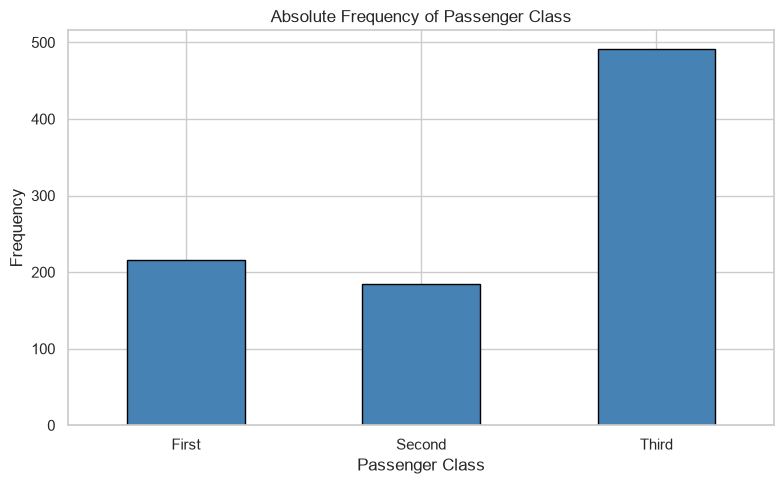

In [4]:
abs_freq.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Absolute Frequency of Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Frequency")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---
## Part II: Probability Analysis

Contingency table between Sex and Survived, then joint, marginal, and conditional probabilities.

In [5]:
contingency = pd.crosstab(df["sex"], df["survived"], margins=True)
print("Contingency Table: Sex vs Survived")
contingency

Contingency Table: Sex vs Survived


survived,0,1,All
sex,,,
female,81,233,314
male,468,109,577
All,549,342,891


In [6]:
joint_prob = pd.crosstab(df["sex"], df["survived"], normalize="all")
print("Joint Probability P(Sex ∩ Survived)")
joint_prob.round(4)

Joint Probability P(Sex ∩ Survived)


survived,0,1
sex,,
female,0.0909,0.2615
male,0.5253,0.1223


In [7]:
marginal_sex = df["sex"].value_counts(normalize=True)
marginal_survived = df["survived"].value_counts(normalize=True)

print("Marginal Probability P(Sex)")
print(marginal_sex.round(4))
print("\nMarginal Probability P(Survived)")
print(marginal_survived.round(4))

Marginal Probability P(Sex)
sex
male      0.6476
female    0.3524
Name: proportion, dtype: float64

Marginal Probability P(Survived)
survived
0    0.6162
1    0.3838
Name: proportion, dtype: float64


In [8]:
cond_survived_given_sex = pd.crosstab(df["sex"], df["survived"], normalize="index")
print("Conditional Probability P(Survived | Sex)")
print(cond_survived_given_sex.round(4))

cond_sex_given_survived = pd.crosstab(df["sex"], df["survived"], normalize="columns")
print("\nConditional Probability P(Sex | Survived)")
print(cond_sex_given_survived.round(4))

Conditional Probability P(Survived | Sex)
survived       0       1
sex                     
female    0.2580  0.7420
male      0.8111  0.1889

Conditional Probability P(Sex | Survived)
survived       0       1
sex                     
female    0.1475  0.6813
male      0.8525  0.3187


---
## Part III: Correlation Analysis

Pearson correlation between Age and Fare (after handling missing values).

In [9]:
age_fare = df[["age", "fare"]].dropna()

print("Rows after dropping missing Age/Fare:", len(age_fare))
print("Missing values remaining:")
print(age_fare.isna().sum())

Rows after dropping missing Age/Fare: 714
Missing values remaining:
age     0
fare    0
dtype: int64


In [10]:
corr_matrix = age_fare.corr(method="pearson")
pearson_r = age_fare["age"].corr(age_fare["fare"], method="pearson")

print(f"Pearson correlation coefficient (Age vs Fare): {pearson_r:.4f}")
corr_matrix

Pearson correlation coefficient (Age vs Fare): 0.0961


,age,fare
age,1.000000,0.096067
fare,0.096067,1.000000


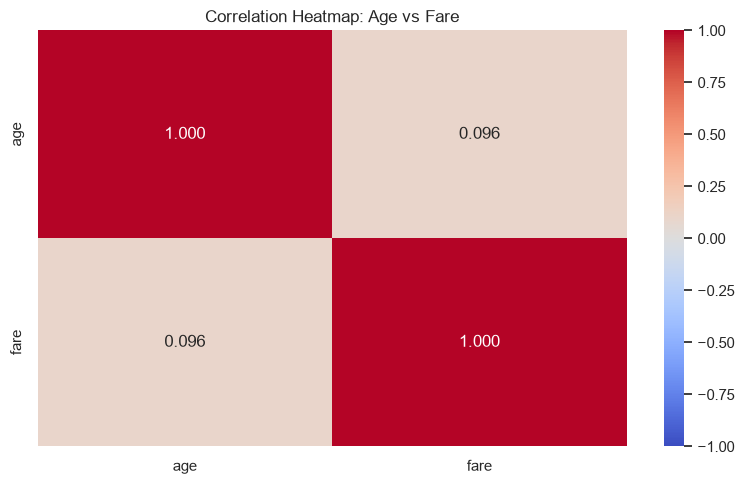

In [11]:
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap: Age vs Fare")
plt.tight_layout()
plt.show()

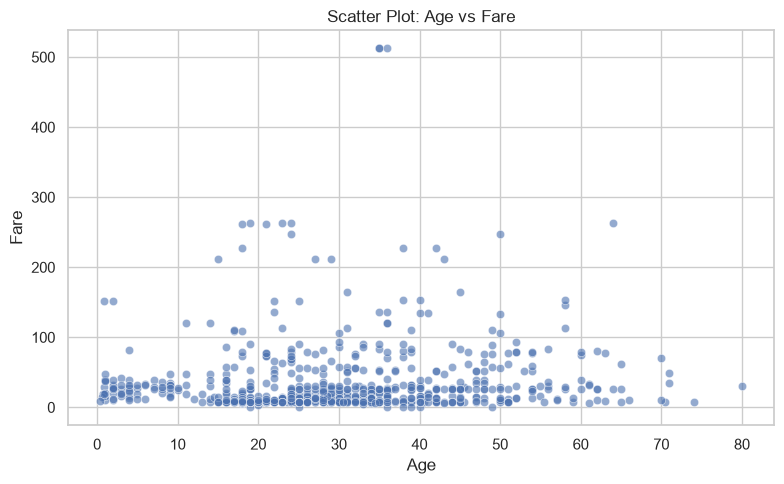

In [12]:
sns.scatterplot(data=age_fare, x="age", y="fare", alpha=0.6)
plt.title("Scatter Plot: Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

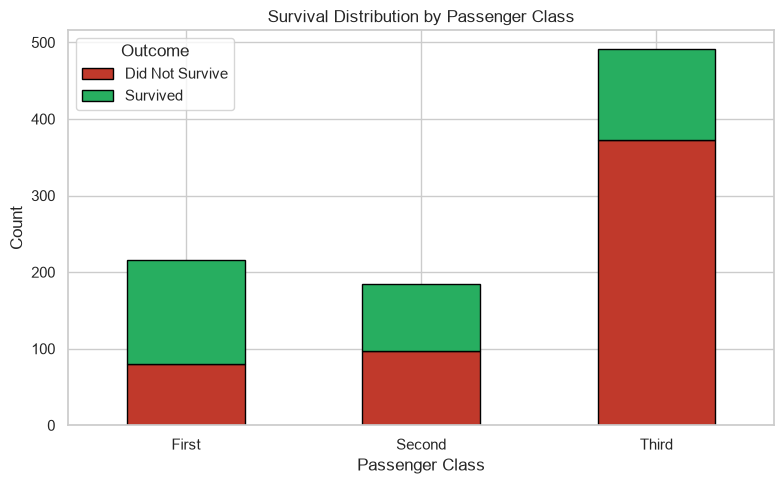

In [13]:
survival_by_class = pd.crosstab(df["class"], df["survived"])
survival_by_class.columns = ["Did Not Survive", "Survived"]

survival_by_class.plot(kind="bar", stacked=True, color=["#c0392b", "#27ae60"], edgecolor="black")
plt.title("Survival Distribution by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

---
## Exercises / Assignments

### Exercise 1: Frequency table for Embarked

In [14]:
embarked_abs = df["embarked"].value_counts()
embarked_rel = df["embarked"].value_counts(normalize=True) * 100
embarked_cum = embarked_abs.cumsum()

embarked_freq = pd.DataFrame({
    "Absolute Frequency": embarked_abs,
    "Relative Frequency (%)": embarked_rel.round(2),
    "Cumulative Frequency": embarked_cum
})
print("Frequency Table for Embarked")
embarked_freq

Frequency Table for Embarked


,Absolute Frequency,Relative Frequency (%),Cumulative Frequency
embarked,,,
S,644,72.44,644
C,168,18.90,812
Q,77,8.66,889


### Exercise 2: Probability that a passenger survived

In [15]:
p_survived = df["survived"].mean()
print(f"P(Survived) = {p_survived:.4f} ({p_survived * 100:.2f}%)")

P(Survived) = 0.3838 (38.38%)


### Exercise 3: Pearson correlation between Age and Fare

In [16]:
print(f"Pearson r (Age, Fare) = {pearson_r:.4f}")

Pearson r (Age, Fare) = 0.0961


### Exercise 4: Stacked bar chart — survival by passenger class

(Already plotted in Part III above.)

### Exercise 5: Interpret the correlation coefficient

The Pearson correlation between Age and Fare is close to **0** (weak positive). This means there is little to no linear relationship between a passenger's age and the fare they paid — older passengers did not systematically pay much higher or lower fares than younger ones.

---
## Observation

- Frequency tables were successfully generated for passenger classes.
- Contingency tables clearly represented the relationship between gender and survival.
- Joint, marginal, and conditional probabilities were computed successfully.
- Missing values in the Age column were handled before correlation analysis.
- Pearson correlation between Age and Fare was calculated.
- Heatmaps and scatter plots effectively visualized the relationship between variables.
- The stacked bar chart showed differences in survival rates among passenger classes.

## Result

Frequency analysis, probability calculations, and correlation analysis were successfully performed using the Titanic dataset. The visualizations enhanced the understanding of relationships between categorical and numerical variables.

## Conclusion

The experiment demonstrated how frequency tables and probability concepts can be applied to real-world datasets using Python. Contingency tables helped compute joint, marginal, and conditional probabilities, while Pearson correlation measured the relationship between Age and Fare. Data visualization techniques such as heatmaps, scatter plots, and stacked bar charts made the analysis more meaningful and easier to interpret.